Práctica 3. Algoritmo de Dijkstra 

Objetivo: Construir un grafo de 8 nodos , calcular la ruta mas corta entre los nodos y reprsentar gráficamente el resultado 


In [4]:
#importar librerias a utilizar 
import networkx as nx  # permite crear y trabjar con grafos 
import matplotlib.pyplot as plt # permite dibujar o graficar los grafos 
import heapq # permite seleccionar el nodo con la menor distancia durante el algoritmo



In [ ]:
# Crear el grafo
G = nx.Graph()

# Agregar las conexiones y sus distancias
conexiones = [
    ('A', 'B', 4),
    ('A', 'C', 2),
    ('B', 'C', 1),
    ('B', 'D', 5),
    ('C', 'D', 8),
    ('C', 'E', 10),
    ('D', 'E', 2),
    ('D', 'F', 6),
    ('E', 'F', 3),
    ('E', 'G', 7),
    ('F', 'G', 1),
    ('F', 'H', 8),
    ('G', 'H', 4)
]

# Agregar las conexiones al grafo
G.add_weighted_edges_from(conexiones)

print("Nodos del grafo:")
print(G.nodes())

print("\nConexiones y distancias:")
print(G.edges(data=True))
# Explicación : Creamos el grafo llamado G , despues se le agrega las conexiones entre los 8 nodos .
#Cada conexion  tiene tres datos ( nodo inicial, nodo final , distancia )

Nodos del grafo:
['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H']

Conexiones y distancias:
[('A', 'B', {'weight': 4}), ('A', 'C', {'weight': 2}), ('B', 'C', {'weight': 1}), ('B', 'D', {'weight': 5}), ('C', 'D', {'weight': 8}), ('C', 'E', {'weight': 10}), ('D', 'E', {'weight': 2}), ('D', 'F', {'weight': 6}), ('E', 'F', {'weight': 3}), ('E', 'G', {'weight': 7}), ('F', 'G', {'weight': 1}), ('F', 'H', {'weight': 8}), ('G', 'H', {'weight': 4})]


3. Mostrar Gráficamente el grafo original 

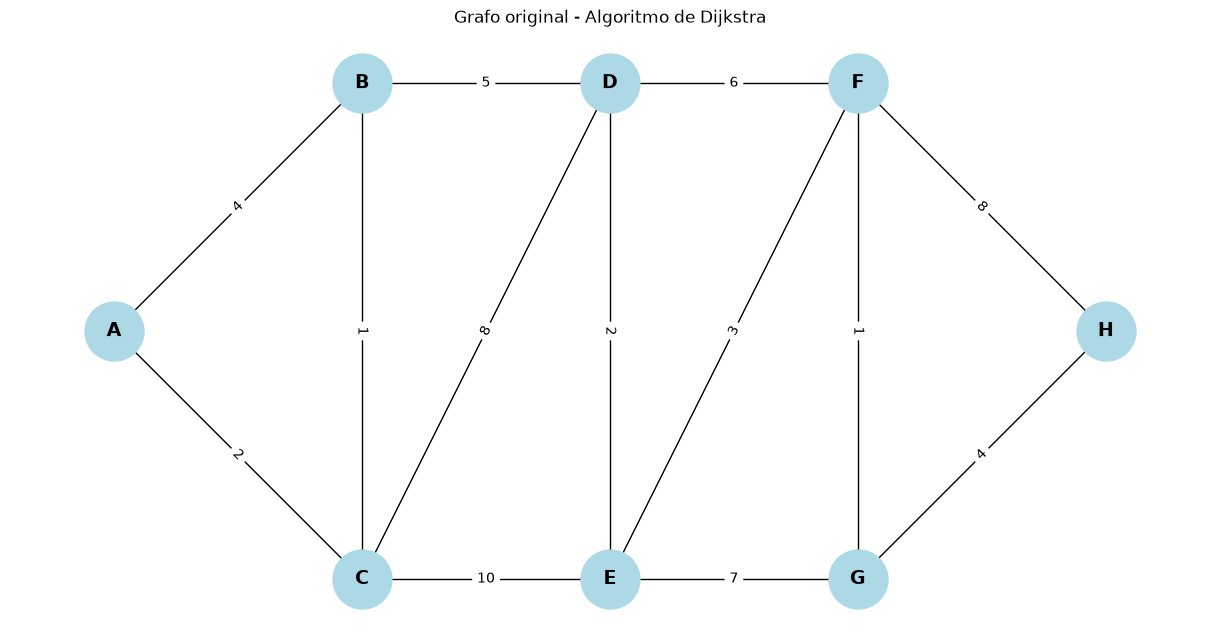

In [6]:
# Definir posiciones de los nodos
pos = {
    'A': (0, 2),
    'B': (2, 3),
    'C': (2, 1),
    'D': (4, 3),
    'E': (4, 1),
    'F': (6, 3),
    'G': (6, 1),
    'H': (8, 2)
}

# Dibujar el grafo
plt.figure(figsize=(12, 6))

nx.draw(
    G, pos,
    with_labels=True,
    node_size=1800,
    node_color="lightblue",
    font_size=14,
    font_weight="bold"
)

# Mostrar los pesos de las conexiones
pesos = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=pesos)

plt.title("Grafo original - Algoritmo de Dijkstra")
plt.axis("off")
plt.show()

4. Programar el algoritmmo de Dijkstra

In [7]:
def dijkstra(grafo, inicio, destino):

    # Inicializar las distancias
    distancias = {nodo: float('inf') for nodo in grafo.nodes}
    anteriores = {nodo: None for nodo in grafo.nodes}

    distancias[inicio] = 0

    # Cola de prioridad
    cola = [(0, inicio)]

    visitados = set()
    paso = 1

    print("INICIO DEL ALGORITMO DE DIJKSTRA\n")

    while cola:

        distancia_actual, nodo_actual = heapq.heappop(cola)

        if nodo_actual in visitados:
            continue

        visitados.add(nodo_actual)

        print(f"Paso {paso}: Se selecciona el nodo {nodo_actual}")
        print(f"Distancia acumulada: {distancia_actual} km")

        # Revisar los vecinos
        for vecino in grafo.neighbors(nodo_actual):

            if vecino not in visitados:

                peso = grafo[nodo_actual][vecino]['weight']

                nueva_distancia = distancia_actual + peso

                if nueva_distancia < distancias[vecino]:

                    distancias[vecino] = nueva_distancia
                    anteriores[vecino] = nodo_actual

                    heapq.heappush(
                        cola,
                        (nueva_distancia, vecino)
                    )

                    print(
                        f"  Se actualiza {vecino}: "
                        f"{nueva_distancia} km"
                    )

        print("Distancias actuales:", distancias)
        print("----------------------------------")

        paso += 1

    # Reconstruir la ruta más corta
    ruta = []
    actual = destino

    while actual is not None:
        ruta.append(actual)
        actual = anteriores[actual]

    ruta.reverse()

    return ruta, distancias[destino], distancias

5. Ejecutar el algoritmo  
indicaremos al algoritmo que queremos viajar de A hasta H

In [8]:
# Definir nodo inicial y destino
inicio = 'A'
destino = 'H'

# Ejecutar Dijkstra
ruta, distancia_total, distancias = dijkstra(
    G, inicio, destino
)

# Mostrar resultados
print("\nRESULTADO FINAL")
print("Ruta más corta:", " -> ".join(ruta))
print("Distancia total:", distancia_total, "km")

INICIO DEL ALGORITMO DE DIJKSTRA

Paso 1: Se selecciona el nodo A
Distancia acumulada: 0 km
  Se actualiza B: 4 km
  Se actualiza C: 2 km
Distancias actuales: {'A': 0, 'B': 4, 'C': 2, 'D': inf, 'E': inf, 'F': inf, 'G': inf, 'H': inf}
----------------------------------
Paso 2: Se selecciona el nodo C
Distancia acumulada: 2 km
  Se actualiza B: 3 km
  Se actualiza D: 10 km
  Se actualiza E: 12 km
Distancias actuales: {'A': 0, 'B': 3, 'C': 2, 'D': 10, 'E': 12, 'F': inf, 'G': inf, 'H': inf}
----------------------------------
Paso 3: Se selecciona el nodo B
Distancia acumulada: 3 km
  Se actualiza D: 8 km
Distancias actuales: {'A': 0, 'B': 3, 'C': 2, 'D': 8, 'E': 12, 'F': inf, 'G': inf, 'H': inf}
----------------------------------
Paso 4: Se selecciona el nodo D
Distancia acumulada: 8 km
  Se actualiza E: 10 km
  Se actualiza F: 14 km
Distancias actuales: {'A': 0, 'B': 3, 'C': 2, 'D': 8, 'E': 10, 'F': 14, 'G': inf, 'H': inf}
----------------------------------
Paso 5: Se selecciona el nodo E

6. Mostrar las tablas de dustancias finales 


In [9]:
# Se mostrar cuánto cuesta llegar desde A hasta cada uno de los otros nodos

print("DISTANCIAS MÍNIMAS DESDE EL NODO A\n")

for nodo, distancia in distancias.items():
    print(f"Nodo {nodo}: {distancia} km")

DISTANCIAS MÍNIMAS DESDE EL NODO A

Nodo A: 0 km
Nodo B: 3 km
Nodo C: 2 km
Nodo D: 8 km
Nodo E: 10 km
Nodo F: 13 km
Nodo G: 14 km
Nodo H: 18 km


7. Dibujar la ruta mas corta 


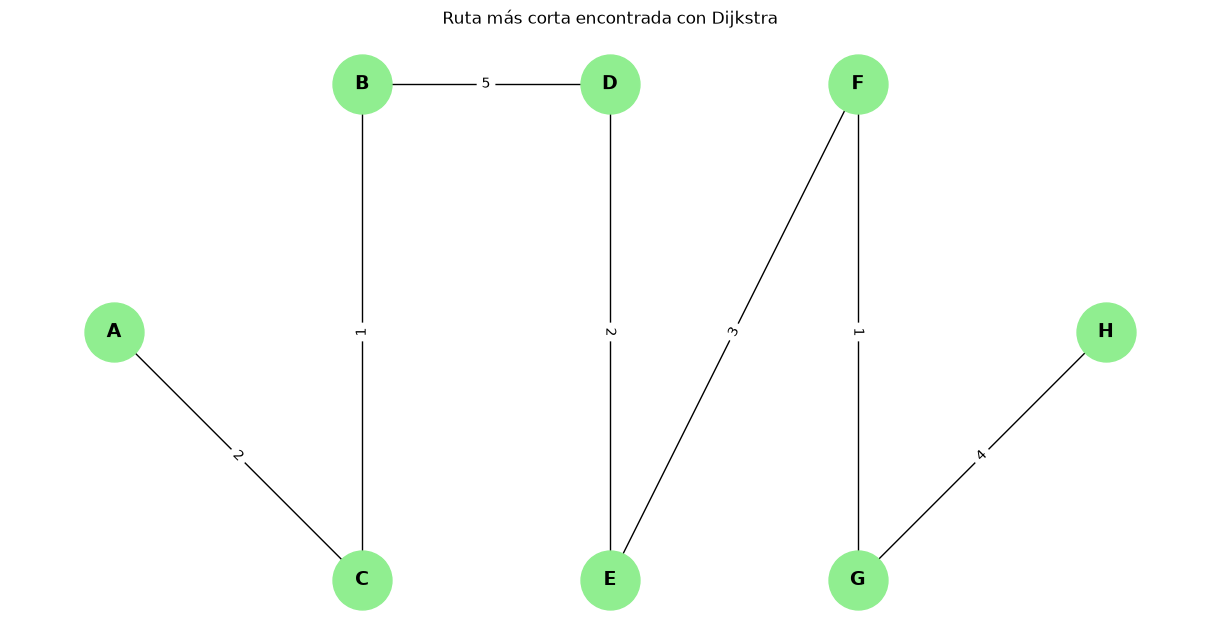

In [10]:
# Crear un nuevo grafo con la ruta encontrada
G_solucion = nx.Graph()

# Agregar las conexiones de la ruta más corta
for i in range(len(ruta) - 1):

    nodo1 = ruta[i]
    nodo2 = ruta[i + 1]

    peso = G[nodo1][nodo2]['weight']

    G_solucion.add_edge(nodo1, nodo2, weight=peso)

# Dibujar la solución
plt.figure(figsize=(12, 6))

nx.draw(
    G_solucion,
    pos,
    with_labels=True,
    node_size=1800,
    node_color="lightgreen",
    font_size=14,
    font_weight="bold"
)

# Mostrar distancias
pesos_solucion = nx.get_edge_attributes(
    G_solucion, 'weight'
)

nx.draw_networkx_edge_labels(
    G_solucion,
    pos,
    edge_labels=pesos_solucion
)

plt.title("Ruta más corta encontrada con Dijkstra")

plt.axis("off")
plt.show()

Podemos observar  el recorrido que se encontro . Se muestran los nodos y distancias de cada conexion utilizada 
para llegar al destino 

8. Calcular y mostrar la suma de las distancias 

In [11]:
print("COMPROBACIÓN DE LA RUTA\n")

suma = 0

for i in range(len(ruta) - 1):

    nodo1 = ruta[i]
    nodo2 = ruta[i + 1]

    peso = G[nodo1][nodo2]['weight']

    suma += peso

    print(f"{nodo1} -> {nodo2} = {peso} km")

print("\nDistancia total:", suma, "km")

COMPROBACIÓN DE LA RUTA

A -> C = 2 km
C -> B = 1 km
B -> D = 5 km
D -> E = 2 km
E -> F = 3 km
F -> G = 1 km
G -> H = 4 km

Distancia total: 18 km


9. Conclusión : En la practica se implemento el algoritmo de Dijkstra utilizando pyhton . Se contruyó un grafo de 8 nodos con diferentes 
conexiones y distancias .
Mediantes el algoritmo se calcularon las distancias mínimas desde el nodo A hasta los demas nodos . Posteriormente se mostro la ruta mas corta paa poder llegar hasta el nodo H .
El resultadio obtenido fue una distancia de 18 kilómetros , siguiendo la ruta 
A-> C -> B -> D-> E - >F -> G -> H
